# Scenarios: LiST adverse and extreme, the 2023 fast run and a depositor generator

**Question:** How far does the survival period of the bank move with the severity of the scenario, with a fast run calibrated before 2023 and with the share of uninsured deposits, and can a run-off estimate be tested against a simulation whose truth is known?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- compose a liquidity scenario from segment run-off rates with the engine and rebuild the survival period of the LiST Adverse and Extreme variants;
- calibrate a fast-run rate on observed runs dated before 2023 only, see the engine refuse the 2023 rows, and say why that refusal is the leakage guard of the case;
- run the grid of the uninsured share and read the monotonicity test;
- use a depositor generator whose exact truth is known to back-test a run-off estimate.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed documents of case C16 (real FDIC call-report aggregates of the bank that failed on 2023-03-10, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `list-adverse.json`, `list-extreme.json` and `fast-run.json`: the three path variants, each with its segments, its daily series, its survival period, its scoring against the run of March 2023 and its sensitivities.
- `models-svb-liquidity.json`: the models document, with the calibration of the fast-run rate on the Table A.1 rows and the configuration, the exact truth and the verification of the depositor generator.

A scenario has a family (idiosyncratic, market-wide or combined) and a phase (acute, from one to five days, or protracted, up to six to twelve months) (BCBS, 2008, Principle 10); the document says which family and phase each variant takes. All files are in `data/derived/C16/`; amounts are in USD thousands.

In [2]:
# Load the four committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("list-adverse", "list-extreme", "fast-run", "models-svb-liquidity"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| baked by riskvalidation", baked, "| installed", rv.__version__)

adverse, extreme = documents["list-adverse"], documents["list-extreme"]
fast, models = documents["fast-run"], documents["models-svb-liquidity"]
rows = {row["variant"]: row for row in adverse["outputs"]["conventions"]["variant_scenarios"]["rows"]}
for variant, row in rows.items():
    print(f"{variant:14s} horizon (days): {row['horizon_days']:4d}")

list-adverse | baked by riskvalidation 1.0.1 | installed 1.0.1
list-extreme | baked by riskvalidation 1.0.1 | installed 1.0.1
fast-run | baked by riskvalidation 1.0.1 | installed 1.0.1
models-svb-liquidity | baked by riskvalidation 1.0.1 | installed 1.0.1
lcr-standard   horizon (days):   30
list-adverse   horizon (days):  125
list-extreme   horizon (days):  125
fast-run       horizon (days):    5
htm-losses     horizon (days):  125


## Method

### Step 1: the parameter sets of the LiST

The ECB's LiST 2019 fixes the daily compounding run-off rate of every open-maturity class under three severities, Baseline, Adverse and Extreme (ECB, 2019, methodological note, Table 3.3). The engine holds them as `list_scenario(severity)`. A class that the set does not hold is refused, never mapped silently, and the LiST shocks are idiosyncratic only. The next cell prints the rates of the classes that the segments of C16 use.

In [3]:
# The daily rates of the classes used by the segments of the case, under the three severities
from riskvalidation.liquidity.scenarios import list_scenario

classes = ("other-retail", "non-operational-non-financial-corporates", "non-operational-other-financial")
print(f"{'class':44s}{'Baseline':>12s}{'Adverse':>12s}{'Extreme':>12s}")
for liquidity_class in classes:
    rates = [list_scenario(severity).class_rate(liquidity_class) for severity in ("baseline", "adverse", "extreme")]
    print(f"{liquidity_class:44s}{rates[0]:12.8f}{rates[1]:12.8f}{rates[2]:12.8f}")

try:
    list_scenario("severe")
except ValueError:
    print("an unknown severity is refused with a ValueError")

class                                           Baseline     Adverse     Extreme
other-retail                                  0.00000000  0.00373218  0.00440873
non-operational-non-financial-corporates      0.00000000  0.00688541  0.01065229
non-operational-other-financial               1.00000000  1.00000000  1.00000000
an unknown severity is refused with a ValueError


### Step 2: composing a scenario and its ladder

A scenario assigns to each segment a class of the parameter set and an opening balance, and holds its daily-rate path over the horizon: `compose_scenario(family, phase, parameter_set, segments, horizon)`. The behavioural outflows are $O_s(d) = B_s \prod_{k<d}(1-q_k)\,q_d$ (notebook 02). The ladder of a variant adds the contractual outflows of the balance sheet (the maturing secured funding) and subtracts the inflows, over the same counterbalancing capacity (notebook 03):

$$\mathrm{NLP}(t) = \mathrm{CBC}(t) - \sum_{s \le t} \Bigl(\sum_{\text{segments}} O_{\text{seg}}(s) + O_{\text{contractual}}(s) - I(s)\Bigr)$$

The next cell composes the Adverse and Extreme scenarios from the segments of each document (class and opening balance), with the family and phase of the committed conventions, adds the contractual flows of the document, and prints the survival day of each variant with the opening balance and the first daily rate of each segment.

In [4]:
# Compose the LiST Adverse and Extreme scenarios and rebuild their ladders from the committed segments
from riskvalidation.liquidity.ladder import net_liquidity_position, survival_period
from riskvalidation.liquidity.scenarios import compose_scenario

built = {}
variants = (("list-adverse", "adverse", adverse), ("list-extreme", "extreme", extreme))
for variant, severity, document in variants:
    lad = document["outputs"]["path"]["ladder"]
    row = rows[variant]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    args = (row["scenario_family"], row["phase"], list_scenario(severity))
    scenario = compose_scenario(*args, segments, row["horizon_days"])
    contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
    inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
    total_outflows = scenario.outflows().sum(axis=0) + contractual
    nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
    built[variant] = (scenario, nlp, survival_period(nlp))
    print(variant, "|", scenario.family, scenario.phase, "| segments:", len(scenario.segments))
    print("   survival day:", built[variant][2].day)

print(f"{'segment':28s}{'opening (USD bn)':>18s}{'rate Adverse':>14s}{'rate Extreme':>14s}")
for seg_a, seg_e in zip(built["list-adverse"][0].segments, built["list-extreme"][0].segments):
    print(f"{seg_a.segment_id:28s}{seg_a.opening / 1e6:18.3f}{seg_a.daily_rates[0]:14.8f}{seg_e.daily_rates[0]:14.8f}")

list-adverse | idiosyncratic protracted | segments: 3
   survival day: 62
list-extreme | idiosyncratic protracted | segments: 3
   survival day: 41
segment                       opening (USD bn)  rate Adverse  rate Extreme
retail-insured                           9.990    0.00373218    0.00440873
non-operational-corporate              151.592    0.00688541    0.01065229
financial                               13.899    1.00000000    1.00000000


Two things stand out. The Extreme severity shortens the survival period (the farther one goes along the severity, the earlier the NLP turns negative), and the uninsured corporate segment, 151.6 billion of 175.5 billion of deposits, dominates both scenarios: its rate is 0.00688541 a day under Adverse and 0.01065229 under Extreme. The financial segment leaves in full on day 1 in both.

### Step 3: the fast run, calibrated before 2023

The 2023 turmoil "reset the speed assumptions" (BCBS, 2023). The product adds a fast-run variant whose rate is not a LiST table but is calibrated on observed runs: the implied daily rate of each row $i$ of Table A.1 is $q_i = 1-(1-F_i)^{1/n_i}$ (notebook 02) and the fitted rate is a statistic of those rates; the calibration rule of the document is the maximum (`maximum-implied-daily-rate`, a stated convention, because the dossiers give no calibration method). The leakage-safe protocol is this: calibrate on the rows dated before 2023 and score on the rows of 2023. The engine enforces it: a call marked `scored=True` refuses a 2023 row. The next cell calibrates, tries the refused call and compares with the committed calibration. The observation of Silicon Valley Bank (85% in 2 days; Federal Reserve, 2023) enters only as a labelled anchor, never as a forecast.

In [5]:
# Calibrate the fast-run rate on the pre-2023 rows, try a 2023 row, and read the anchor
from riskvalidation.liquidity.runoff import TABLE_A1
from riskvalidation.liquidity.scenarios import anchor_from_observation, fast_run_scenario

pre_2023 = [run for run in TABLE_A1 if run.year < 2023]
fit = fast_run_scenario(pre_2023, "maximum-implied-daily-rate", scored=True)

print("rows used:", [run.row_id for run in pre_2023])
print("implied daily rates:", [round(q, 6) for q in fit.implied_rates])
print("fitted rate (maximum):", round(fit.daily_rate, 8))

try:
    fast_run_scenario(list(TABLE_A1), "maximum-implied-daily-rate", scored=True)
except ValueError:
    print("a scored call with a 2023 row is refused by the engine (ValueError)")

anchor = anchor_from_observation(0.85, 2)
print("anchor: outflow share and days:", anchor["outflow_share"], anchor["days"])
print("implied daily rate of the anchor:", round(anchor["implied_daily_rate"], 6))
print("the anchor is a forecast claim:", anchor["forecast_claim"])

rows used: ['icesave-2008', 'northern-rock-2007', 'wamu-2008', 'indymac-2008']
implied daily rates: [0.002971, 0.054258, 0.010481, 0.005938]
fitted rate (maximum): 0.05425839
a scored call with a 2023 row is refused by the engine (ValueError)
anchor: outflow share and days: 0.85 2
implied daily rate of the anchor: 0.612702
the anchor is a forecast claim: False


The fast-run scenario puts the fitted rate on the uninsured corporate segment (the one class that a `FastRun` parameter set holds, `concentrated-uninsured`) and keeps the LiST Adverse rates on the other segments, over the acute horizon of 5 days. The next cell composes it, rebuilds its ladder as in step 2, and then scores the variant against the runs of 2023 that its 5-day ladder can reach (the rows beyond the horizon cannot be scored) with the back-test of the product.

In [6]:
# Compose the fast run: the fitted rate on the uninsured corporate segment, LiST Adverse on the rest
from riskvalidation.liquidity.scenarios import Scenario

lad = fast["outputs"]["path"]["ladder"]
row = rows["fast-run"]
family, phase, horizon = row["scenario_family"], row["phase"], row["horizon_days"]
segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
others = {k: v for k, v in segments.items() if k != "non-operational-corporate"}
concentrated = {"non-operational-corporate": ("concentrated-uninsured", segments["non-operational-corporate"][1])}
rest = compose_scenario(family, phase, list_scenario("adverse"), others, horizon)
corporate = compose_scenario(family, phase, fit, concentrated, horizon)
by_id = {s.segment_id: s for s in (*rest.segments, *corporate.segments)}
fast_scenario = Scenario(family, phase, horizon, tuple(by_id[k] for k in segments))

contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
total_outflows = fast_scenario.outflows().sum(axis=0) + contractual
fast_nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
fast_result = survival_period(fast_nlp)

print("NLP of the 5 days (USD billions):", [round(float(x) / 1e6, 2) for x in fast_nlp])
print("survives the horizon:", fast_result.survives)

NLP of the 5 days (USD billions): [13.8, 27.42, 34.3, 27.25, 20.57]
survives the horizon: True


The fast run is scored against the runs of 2023 that its 5-day ladder reaches: the modelled share is the cumulative outflow of the segments over the deposit base of the model, and the back-test of the product sets it against the share the board review states and the one the call report supports (the realised shares of the denominators of the document).

In [7]:
# Score the fast run against the 2023 runs it can reach, and back-test it at the two-day event horizon
from riskvalidation.validation.liquidity import runoff_adequacy_back_test

evaluation = fast["outputs"]["scoring"]
base_deposits = evaluation["model_deposit_base"]
outflow_by_day = np.cumsum(fast_scenario.outflows().sum(axis=0))
print(f"{'Table A.1 row':22s}{'days':>6s}{'observed':>10s}{'modelled':>10s}")
for run in TABLE_A1:
    if run.year == 2023 and run.days <= fast_scenario.horizon:
        modelled = outflow_by_day[run.days - 1] / base_deposits
        print(f"{run.row_id:22s}{run.days:6d}{run.outflow_share:10.2f}{modelled:10.4f}")

event_days = evaluation["event"]["horizon_days"]
modelled_event = outflow_by_day[event_days - 1] / base_deposits
for board in evaluation["denominators"]:
    test = runoff_adequacy_back_test(
        modelled_event, board["realised_share"], compared_at="event-horizon", denominator=board["id"]
    )
    print(f"{board['id']:20s} realised {board['realised_share']:.4f} | ratio {test.statistic:.6f} | {test.light.value}")

Table A.1 row           days  observed  modelled
svb-2023                   2      0.85    0.1708
svb-uk-2023                1      0.30    0.1263
signature-2023             1      0.20    0.1263
board-stated-share   realised 0.8500 | ratio 0.200976 | red
call-report-dep      realised 0.7983 | ratio 0.213999 | red


The next cell draws the NLP of the three variants on one axis: the Adverse and Extreme paths over 125 days and the five days of the fast run.

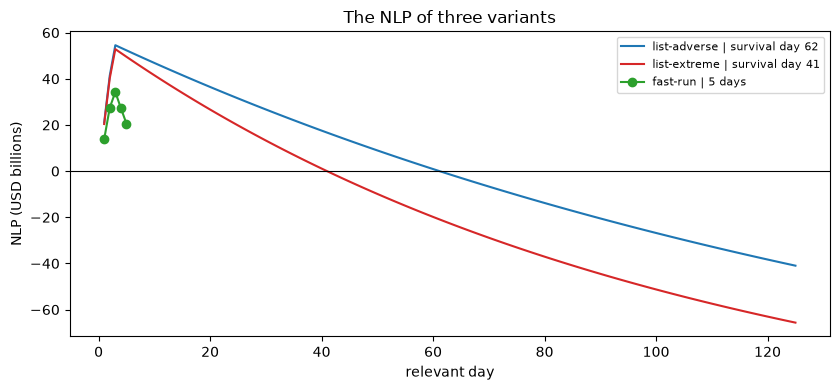

In [8]:
# Draw the NLP of the three variants: LiST Adverse and Extreme over 125 days, the fast run over its 5 days
fig, ax = plt.subplots(figsize=(8.5, 4))
for variant, color in (("list-adverse", "tab:blue"), ("list-extreme", "tab:red")):
    nlp_path, result = built[variant][1], built[variant][2]
    label = f"{variant} | survival day {result.day}"
    ax.plot(np.arange(1, len(nlp_path) + 1), nlp_path / 1e6, color=color, label=label)
ax.plot(np.arange(1, len(fast_nlp) + 1), fast_nlp / 1e6, color="tab:green", marker="o", label="fast-run | 5 days")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("relevant day")
ax.set_ylabel("NLP (USD billions)")
ax.set_title("The NLP of three variants")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The Extreme path crosses zero on day 41 and the Adverse path on day 62: the farther along the severity, the earlier the position turns negative. The five green points are the fast run, which stays positive, between 13.80 and 34.30 billion USD, only because its horizon ends on day 5: its rate is the fastest of the three, yet the ladder is too short to exhaust the CBC. Read the scoring above with that in mind: the fast run models 0.1708 of the deposit base in the two days in which SVB lost 0.85, a ratio of about a fifth, red. The figure shows the NLP, not the plausibility of the rate.

### Step 4: the grid of the uninsured share

The run risk of a bank rises with the share of its deposits that nobody insures (Diamond and Dybvig, 1983, is the theory; the uninsured share is the driver the research dossier keeps). `uninsured_share_grid` keeps the total of the two balances and moves a share $\sigma$ to the uninsured one:

$$\mathrm{uninsured} = (D_{\text{ins}} + D_{\text{unins}})\,\sigma, \qquad \mathrm{insured} = (D_{\text{ins}} + D_{\text{unins}})\,(1-\sigma)$$

For each share the ladder is run again with the new openings. The survival period must not lengthen as the share rises; the test `liq.uninsured_share_sensitivity` takes the largest increase of the survival period along the grid, in days. The next cell reruns the ladder at each share of the grid of the document and prints the survival day of each, with the result of the monotonicity test.

In [9]:
# Rerun the LiST Adverse ladder at each uninsured share of the grid, and test the monotonicity
from riskvalidation.liquidity.scenarios import uninsured_share_grid
from riskvalidation.validation.liquidity import uninsured_share_sensitivity

lad = adverse["outputs"]["path"]["ladder"]
row = rows["list-adverse"]
base = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
shares = [entry["share"] for entry in adverse["outputs"]["sensitivities"]["uninsured_share"]]
contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
args = (row["scenario_family"], row["phase"], list_scenario("adverse"))
insured_class, insured_opening = base["retail-insured"]
corporate_class, corporate_opening = base["non-operational-corporate"]

days = []
for insured, uninsured in uninsured_share_grid(insured_opening, corporate_opening, shares):
    openings = dict(base)
    openings["retail-insured"] = (insured_class, insured)
    openings["non-operational-corporate"] = (corporate_class, uninsured)
    scenario = compose_scenario(*args, openings, row["horizon_days"])
    nlp = net_liquidity_position(np.array(lad["cbc_total"]), scenario.outflows().sum(axis=0) + contractual, inflows)
    outcome = survival_period(nlp)
    days.append(None if outcome.survives else outcome.day)

sensitivity = uninsured_share_sensitivity(shares, days)
print("uninsured shares:", shares)
print("survival days:", days)
print("largest increase along the grid (days):", sensitivity.statistic, "| light:", sensitivity.light.value)

uninsured shares: [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
survival days: [77, 75, 73, 71, 69, 68, 66, 64, 63, 61]
largest increase along the grid (days): 0.0 | light: green


The next cell draws the survival period against the uninsured share.

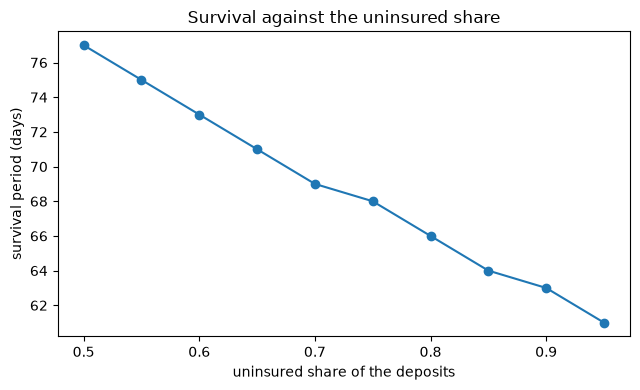

In [10]:
# Draw the survival period of the LiST Adverse ladder against the uninsured share of the deposits
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(shares, days, marker="o", color="tab:blue")
ax.set_xlabel("uninsured share of the deposits")
ax.set_ylabel("survival period (days)")
ax.set_title("Survival against the uninsured share")
fig.tight_layout()
plt.show()

The line only goes down: from 77 days when half of the deposits are uninsured to 61 days when 95% are, a loss of about one to two days for every five points of share. That is the sign the test checks, and its largest increase along the grid is 0.0 days. The shape is gentle because moving deposits from the insured retail segment to the corporate one raises the outflow only by the gap between their two daily rates (0.00373218 and 0.00688541 under Adverse), and the financial segment, which leaves in full on day 1, does not change. The figure does not say which share the bank really had; that comes from the call report.

### Step 5: a depositor generator with a known truth

A run-off estimate can only be tested against a truth that is known. `DepositorGenerator` draws depositors of several segments through a systemic two-state Markov chain over the days (calm or stress, one chain shared by all depositors); a depositor still deposited on day $d$ withdraws with the hazard $h_{\text{calm}}$ or $h_{\text{stress}}$ of the state of that day. Because the model is small its truth is exact: with $u_d$ the row vector of the probabilities of being still deposited in each state, $P$ the transition matrix between the states and $\odot$ the elementwise product,

$$u_1 = (1 - h_{\text{calm}},\; 0), \qquad u_{d+1} = (u_d P) \odot (1 - h_{\text{calm}},\; 1 - h_{\text{stress}}), \qquad F_{\text{truth}}(n) = 1 - \textstyle\sum u_n$$

The transition law of the stress state (a daily entry probability of 0.01 and an exit probability of 0.05) has no source in the dossiers: it is a convention of the engine, stated as such (UNVERIFIED). The segments, shares and hazards come from the models document, which calibrated the stress hazard of the corporate segment with the fast-run rate. The next cell rebuilds the generator from the committed configuration and computes its exact truth at four horizons.

In [11]:
# Rebuild the generator from the committed configuration and compute its exact truth
from riskvalidation.liquidity.deposits import DepositorConfig, DepositorGenerator, DepositorSegment

generator_doc = models["fit"]["generator"]
config = generator_doc["config"]
# one stress chain is shared by every depositor: its two probabilities are repeated on each segment row
((p_enter, p_exit),) = {(s["p_enter_stress"], s["p_exit_stress"]) for s in config["segments"]}
segments = tuple(
    DepositorSegment(s["segment"], s["share_of_deposits"], s["calm_daily_hazard"], s["stress_daily_hazard"])
    for s in config["segments"]
)
settings = DepositorConfig(segments, config["n_depositors"], config["horizon_days"], p_enter, p_exit)
generator = DepositorGenerator(settings)
truth = generator.truth()["outflow_rate"]

print("depositors per segment and horizon:", config["n_depositors"], config["horizon_days"])
for key, path in truth.items():
    print(f"{key:28s}", {day: round(float(path[day - 1]), 6) for day in (2, 5, 30, 125)})

depositors per segment and horizon: 1000 125
retail-insured               {2: 3.7e-05, 5: 0.00035, 30: 0.009646, 125: 0.062623}
non-operational-corporate    {2: 0.000543, 5: 0.004852, 30: 0.100707, 125: 0.44551}
financial                    {2: 0.01, 5: 0.039404, 30: 0.252828, 125: 0.712416}


Now the back-test. The estimate is the mean cumulative outflow share of a seeded sample of simulated runs, at the horizons of the document (2, 5, 30 and 125 days); its Monte Carlo standard error is the standard deviation over the square root of the number of draws. The test `liq.runoff_vs_generator_truth` takes the largest distance to the truth in standard errors: green up to 2, amber up to 3, red above (internal gates of the product). This cell uses 2,000 draws, which takes a fraction of a second.

In [12]:
# Back-test the simulated run-off against the exact truth of the generator
from riskvalidation.validation.liquidity import runoff_vs_generator_truth

draws = 2000
rng = np.random.default_rng(42)
samples = {key: np.empty((draws, config["horizon_days"])) for key in truth}
for i in range(draws):
    for key, path in generator.draw(rng)["outflow_rate"].items():
        samples[key][i] = path

horizons = (2, 5, 30, 125)
pairs = [(k, h) for k in truth for h in horizons]
estimated = np.array([samples[k][:, h - 1].mean() for k, h in pairs])
exact_values = np.array([truth[k][h - 1] for k, h in pairs])
standard_errors = np.array([samples[k][:, h - 1].std(ddof=1) / np.sqrt(draws) for k, h in pairs])

check = runoff_vs_generator_truth(estimated, exact_values, standard_errors)
print("draws:", draws, "| checks:", check.n)
print("largest distance in standard errors:", round(check.statistic, 4), "| light:", check.light.value)

draws: 2000 | checks: 12
largest distance in standard errors: 1.3558 | light: green


The next cell draws the exact truth of the corporate segment of the generator with the simulated means at the four horizons and their two-standard-error bars.

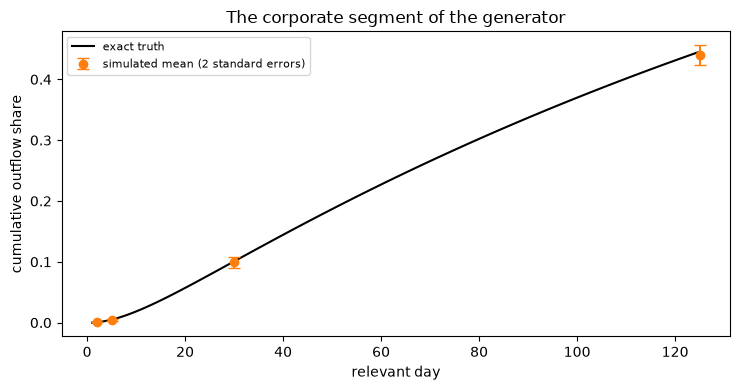

In [13]:
# Draw the exact truth of the corporate segment against the simulated means and their standard errors
key = "non-operational-corporate"
position = [pairs.index((key, h)) for h in horizons]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(np.arange(1, 126), truth[key], color="black", label="exact truth")
ax.errorbar(
    horizons, estimated[position], yerr=2 * standard_errors[position],
    fmt="o", color="tab:orange", capsize=4, label="simulated mean (2 standard errors)",
)
ax.set_xlabel("relevant day")
ax.set_ylabel("cumulative outflow share")
ax.set_title("The corporate segment of the generator")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The black curve is the exact cumulative outflow of the corporate segment, computed from the two-state chain: 0.000543 at day 2, 0.004852 at day 5, 0.100707 at day 30 and 0.445510 at day 125. The orange points are the means of 2,000 seeded simulated runs, and every bar of two standard errors contains the curve; the largest distance over the twelve checks is 1.3558 standard errors, inside the green gate of 2. The check tells that the estimator and the arithmetic agree with a mechanism known exactly. It does not tell that the mechanism resembles a real run, because the law of the stress state is a convention of the engine.

## Results

**Answer:** The survival period falls from day 62 under LiST Adverse to day 41 under Extreme, and from 77 days to 61 as the uninsured share of the deposits goes from 0.5 to 0.95. The fast run, calibrated on the four rows before 2023 at a daily rate of 0.05425839, never turns negative within its 5 days, yet it models only 0.1708 of the deposit base in the two days in which SVB lost 0.85 (a ratio of 0.200976, red). A depositor simulation with an exact truth lies within 1.3558 standard errors of it, which makes a run-off estimate testable.

- **Composition.** Composing the segments with the engine gives the NLP turning negative on day 62 under LiST Adverse and on day 41 under Extreme. The uninsured corporate segment (151.592 billion USD, a daily rate of 0.00688541 under Adverse and 0.01065229 under Extreme) dominates both, and the financial segment (13.899 billion) leaves in full on day 1.
- **The fast run.** The rate fitted on the four pre-2023 rows is 0.05425839 (Northern Rock, 20% in 4 days), and the engine refuses a 2023 row in a scored call. With that rate the 5-day ladder never turns negative (the NLP stays between 13.80 and 34.30 billion, its lowest value on day 1), so it survives its horizon. Yet it models 0.1708 of the deposit base in the two days in which SVB lost 0.85, and 0.1263 in the one day in which SVB UK lost 0.30 and Signature 0.20. Calibrated only on what happened before 2023, even the fastest rate falls well short of the run it is scored against.
- **The uninsured share.** Across the ten shares from 0.5 to 0.95 the survival period falls from 77 to 61 days, and the monotonicity test is green with a largest increase of 0.0 days.
- **The generator.** The exact truth of the generator for the corporate segment is 0.000543, 0.004852, 0.100707 and 0.445510 at 2, 5, 30 and 125 days. With 2,000 seeded draws the largest distance to the truth is 1.3558 standard errors, green. The check is as good as the generator: the stress law is a convention, so it tests the arithmetic of an estimator against a known mechanism, not the mechanism against reality.

What this notebook does not show: the multiplier of the run-off at which the survival period falls to a target (notebook 06), nor the comparison of the smooth and the fast run-offs as a state-of-the-art question (notebook 07). Every survival period belongs to synthetic behaviour on real aggregates.

## Summary

- A scenario is a family, a phase, and per segment a class and an opening balance; the engine composes the daily rates and the outflows, and the ladder of the document is rebuilt.
- The fast-run rate is calibrated on the rows before 2023 only, and the engine refuses a 2023 row in a scored call: the calibration split is a rule of the code, not a promise.
- The survival period is non-increasing in the uninsured share and in the severity, and the tests check both.
- A generator with an exact truth turns a run-off estimate into a testable statement, in standard errors of the Monte Carlo.

**What to try next.** Change the seed or the number of draws and watch the largest distance to the truth move; then continue with notebook 05.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Table 3.3. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Diamond, D. W. and Dybvig, P. H. (1983), Bank runs, deposit insurance, and liquidity, Journal of Political Economy 91(3). https://doi.org/10.1086/261155